# TS00 — Foundations, targets, and negative controls

## Goal
Define two equal-priority forecast tracks over **1–5 observed sessions**:
future causal smoothed log levels and future actual log returns using smoothed inputs.
Before comparing sophisticated models, demonstrate the predictability introduced by a filter.
This is a methods laboratory, not evidence of trading profitability.

## Observed results

The 30,000 independent conditional simulations reproduce the analytic EMA mean. At horizon five, smoothed persistence has **10.41 times** the filter-aware forecast's conditional MSE in this specified null. This is filter catch-up, not return predictability. Both research tracks have separate scorecards; current-origin future labels remain immature.

## Setup
Run with a Python environment containing the dependencies in `requirements.txt`.
No download, credentials, earlier notebook execution, or hidden kernel state is required.
All figures and tables are saved in `outputs/TS00_Foundations_and_Targets`.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'tslab').is_dir())
sys.path.insert(0, str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tslab.smoothing import FilterSpec, CausalSmoother, smooth
from tslab.data import synthetic_signal, load_snapshot
from tslab.targets import make_targets, mature_labels
from tslab.evaluation import benchmark, scorecard, paired_block_difference
from tslab.diagnostics import audit_replay, response_metrics, latent_scores, impulse_response
from tslab.reporting import configure_plots, save_figure, write_manifest, filter_configs
configure_plots()
COLORS = dict(zip(['Unfiltered','EMA','DEMA','TEMA','KAMA','Butterworth','Bessel',
                  'Endpoint SG','Weighted local linear','Trailing spline','Kalman (unmatched)'],
                 ['#777777','#0072B2','#D55E00','#009E73','#CC79A7','#E69F00','#56B4E9',
                  '#AA4499','#332288','#882255','#117733']))
SEED = 1731
OUT = ROOT/'outputs'/'TS00_Foundations_and_Targets'
OUT.mkdir(parents=True, exist_ok=True)

## Steps
### 1. Define the data and targets
We begin with a known trend/cycle and IID observation noise. Synthetic weekday
timestamps are an observation schedule, not an exchange calendar. Session horizons
advance through the index supplied by the data source; there is no calendar filling.

For $x_t=\log P_t$, the two labels are $s_{t+h}$ and $x_{t+h}-x_t$.
The smoothed label at $t+h$ is the endpoint issued using information only through $t+h$.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS00_Foundations_and_Targets/01_target_definition.png')


,origin,track,horizon,target_end,actual
3660,2021-07-06,smoothed,1,2021-07-07,4.714650
3661,2021-07-06,smoothed,2,2021-07-08,4.714551
3662,2021-07-06,smoothed,3,2021-07-09,4.718361
3663,2021-07-06,smoothed,4,2021-07-12,4.721400
3664,2021-07-06,smoothed,5,2021-07-13,4.719945
3665,2021-07-07,smoothed,1,2021-07-08,4.714551
3666,2021-07-07,smoothed,2,2021-07-09,4.718361
3667,2021-07-07,smoothed,3,2021-07-12,4.721400
3668,2021-07-07,smoothed,4,2021-07-13,4.719945
3669,2021-07-07,smoothed,5,2021-07-14,4.729375


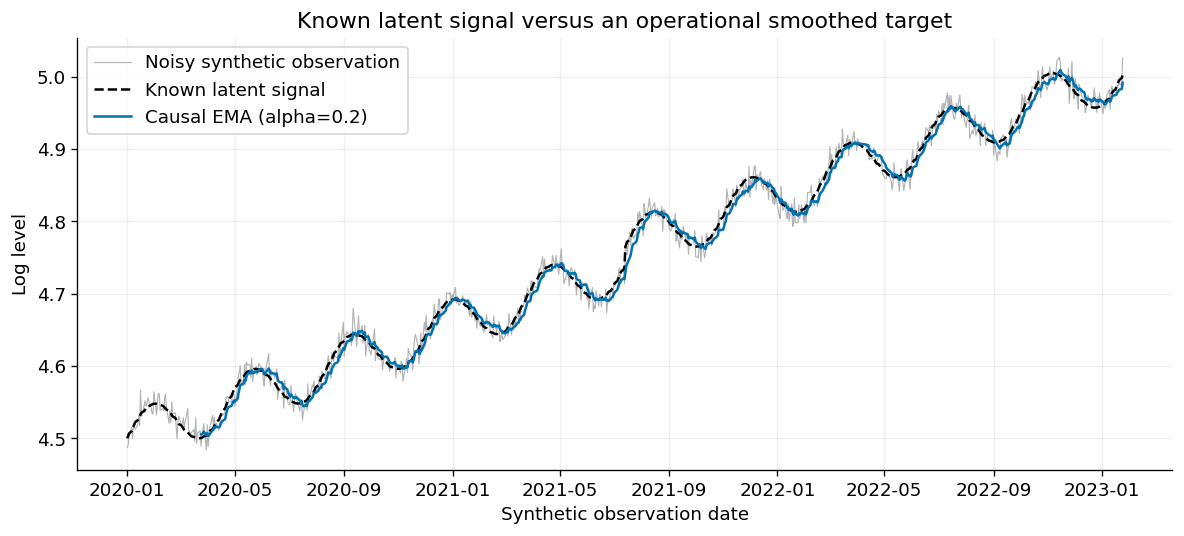

In [2]:
demo = synthetic_signal(seed=SEED)
spec = FilterSpec(kind='ema', alpha=.2, warmup=60)
x = demo.observed.rename('log_price')
s = pd.Series(smooth(x, spec), index=x.index, name='smoothed')
targets = make_targets(x, s)
as_of = x.index[400]
eligible = mature_labels(targets, as_of, require_all_horizons=True)
assert (eligible.available_at <= as_of).all()
assert eligible.groupby(['track','origin']).horizon.nunique().eq(5).all()
targets.to_csv(OUT/'targets.csv', index=False)
eligible.tail(10).to_csv(OUT/'mature_label_example.csv', index=False)
display(eligible.tail(10)[['origin','track','horizon','target_end','actual']].round(6))
fig, ax = plt.subplots()
ax.plot(demo.index, demo.observed, color='.7', lw=.7, label='Noisy synthetic observation')
ax.plot(demo.index, demo.latent, color='black', ls='--', label='Known latent signal')
ax.plot(s.index, s, label='Causal EMA (alpha=0.2)')
ax.set(title='Known latent signal versus an operational smoothed target', ylabel='Log level', xlabel='Synthetic observation date')
ax.legend(ncol=1)
save_figure(fig, OUT, '01_target_definition');

The filtered series is an operational target, not latent truth. Its warm-up remains
missing. The last five-session labels remain unavailable until their end timestamps.

### 2. Derive and test a filter-aware null
Assume $x_t$ is a martingale. For an EMA with $q=1-\alpha$,
$$E[s_{t+h}\mid\mathcal F_t]=q^h s_t+(1-q^h)x_t.$$
Under independent future returns of variance $\sigma^2$, its conditional forecast MSE is
$$\sigma^2\sum_{j=1}^h(1-q^j)^2.$$
Holding the smoothed value constant adds the squared deterministic catch-up term.
These identities describe the assumed null, not a market law.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS00_Foundations_and_Targets/02_filter_mechanics_null.png')


,horizon,analytic_mean,MC_mean,MC_mean_SE,analytic_MSE,MC_filter_MSE,MC_persistence_MSE,MC_zero_return_MSE,analytic_zero_return_MSE
0,1,0.960000,0.959991,0.000012,0.000004,0.000004,0.000104,0.000101,0.0001
1,2,0.968000,0.967978,0.000024,0.000017,0.000017,0.000340,0.000198,0.0002
2,3,0.974400,0.974379,0.000037,0.000041,0.000041,0.000635,0.000298,0.0003
3,4,0.979520,0.979493,0.000050,0.000076,0.000075,0.000945,0.000396,0.0004
4,5,0.983616,0.983585,0.000063,0.000121,0.000120,0.001248,0.000496,0.0005


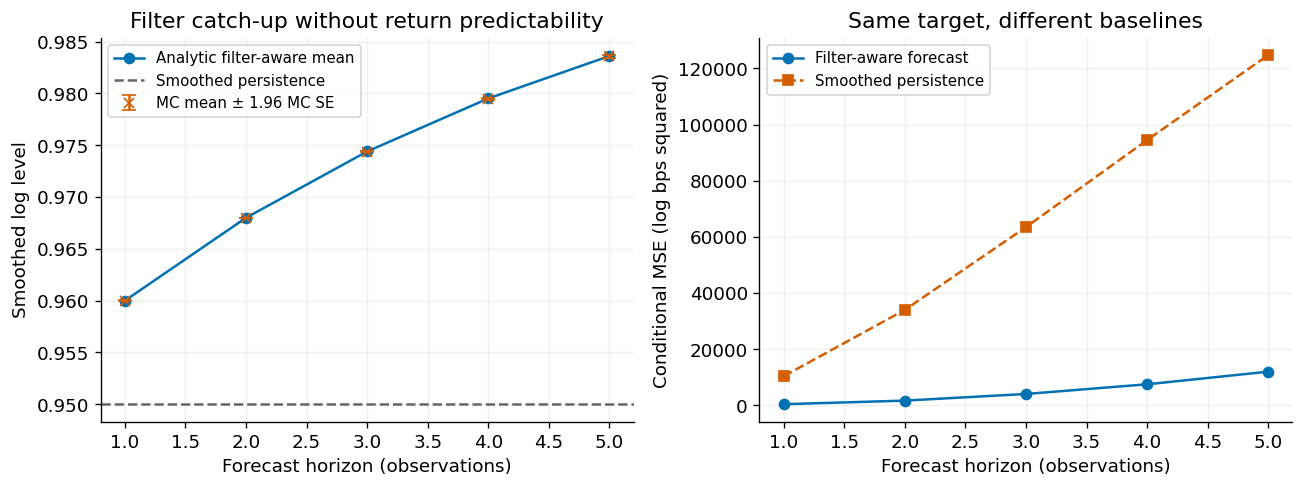

In [3]:
rng = np.random.default_rng(SEED)
draws, sigma, current_x, current_s = 30000, .01, 1., .95
future_x = current_x + rng.normal(0, sigma, (draws,5)).cumsum(axis=1)
future_s = np.empty_like(future_x)
last = np.repeat(current_s, draws)
for j in range(5):
    last = .2*future_x[:,j] + .8*last
    future_s[:,j] = last
h = np.arange(1,6)
null_mean = .8**h*current_s + (1-.8**h)*current_x
theory_mse = sigma**2*np.cumsum((1-.8**h)**2)
simulation = pd.DataFrame({'horizon':h, 'analytic_mean':null_mean,
    'MC_mean':future_s.mean(axis=0), 'MC_mean_SE':future_s.std(axis=0,ddof=1)/np.sqrt(draws),
    'analytic_MSE':theory_mse, 'MC_filter_MSE':np.mean((future_s-null_mean)**2, axis=0),
    'MC_persistence_MSE':np.mean((future_s-current_s)**2,axis=0),
    'MC_zero_return_MSE':np.mean((future_x-current_x)**2,axis=0),
    'analytic_zero_return_MSE':sigma**2*h})
simulation.to_csv(OUT/'martingale_control.csv', index=False)
assert np.all(np.abs(simulation.MC_mean-simulation.analytic_mean) < 5*simulation.MC_mean_SE)
display(simulation.round(7))
fig, axes = plt.subplots(1,2, figsize=(11,4.2))
axes[0].plot(h, null_mean, 'o-', label='Analytic filter-aware mean')
axes[0].errorbar(h, future_s.mean(axis=0), yerr=1.96*simulation.MC_mean_SE,
                 fmt='x', capsize=4, label='MC mean ± 1.96 MC SE')
axes[0].axhline(current_s, color='.4', ls='--', label='Smoothed persistence')
axes[0].set(ylabel='Smoothed log level', title='Filter catch-up without return predictability')
axes[1].plot(h, simulation.MC_filter_MSE*1e8, 'o-', label='Filter-aware forecast')
axes[1].plot(h, simulation.MC_persistence_MSE*1e8, 's--', label='Smoothed persistence')
axes[1].set(ylabel='Conditional MSE (log bps squared)', title='Same target, different baselines')
for ax in axes:
    ax.set_xlabel('Forecast horizon (observations)'); ax.legend(fontsize=9)
save_figure(fig, OUT, '02_filter_mechanics_null');

The error bars quantify Monte Carlo error in the estimated conditional mean, not
prediction intervals for a future outcome. Filter catch-up alone explains why
smoothed persistence is an inadequate sole benchmark.

### 3. Score both tracks on a random-walk negative control
Parameters are fixed, with no model selection. The smoothed track compares persistence,
smoothed-slope extrapolation, and unchanged/drift price paths propagated through saved filter state.
The return track compares a smoothed-slope candidate against zero and historical raw-drift baselines.
Raw drift is an explicitly labeled benchmark comparator, not a smoothed-only candidate.

Out[1]: PosixPath('/Users/trush/.codex/.chatgpt-projects/g-p-6ac01b41a6988191a4168a93e414b122/forecasting_library/outputs/TS00_Foundations_and_Targets/03_separate_scorecards.png')


,horizon,model,n,RMSE,MSE_skill
15,1,filter_drift,190,0.00189,-0.00306
16,1,filter_nochange,190,0.00189,0.00000
17,1,persistence,190,0.00318,-1.84336
18,1,smooth_slope,190,0.00202,-0.14471
19,2,filter_drift,190,0.00394,-0.02150
20,2,filter_nochange,190,0.00390,0.00000
21,2,persistence,190,0.00596,-1.33409
22,2,smooth_slope,190,0.00440,-0.27289
23,3,filter_drift,190,0.00597,-0.03765
24,3,filter_nochange,190,0.00586,0.00000


,horizon,model,n,RMSE,MSE_skill
0,1,raw_drift,190,0.00944,-0.00306
1,1,smooth_slope,190,0.01009,-0.14471
2,1,zero,190,0.00943,0.00000
3,2,raw_drift,190,0.01363,-0.03001
4,2,smooth_slope,190,0.01529,-0.29745
5,2,zero,190,0.01343,0.00000
6,3,raw_drift,190,0.01618,-0.04582
7,3,smooth_slope,190,0.01950,-0.51970
8,3,zero,190,0.01582,0.00000
9,4,raw_drift,190,0.01900,-0.05977


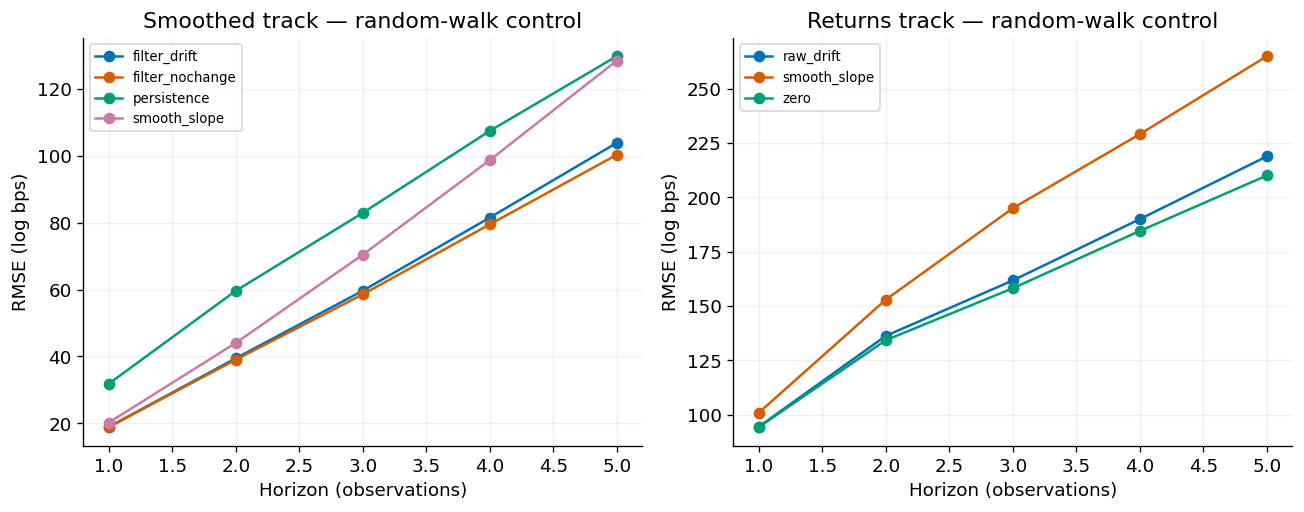

In [4]:
rw = pd.Series(4+np.r_[0., np.random.default_rng(SEED+1).normal(0,.01,1199)].cumsum(),
               index=pd.bdate_range('2020-01-01', periods=1200), name='log_price')
records, rw_s = benchmark(rw, spec, start=250, step=5, filter_id='EMA_0.2')
scores = scorecard(records)
records.to_csv(OUT/'random_walk_forecasts.csv', index=False)
scores.to_csv(OUT/'random_walk_scores.csv', index=False)
for track in ['smoothed','returns']:
    display(scores.loc[scores.track==track, ['horizon','model','n','RMSE','MSE_skill']].round(5))
fig, axes = plt.subplots(1,2, figsize=(11,4.4))
for ax, track in zip(axes, ['smoothed','returns']):
    for model, part in scores[scores.track==track].groupby('model'):
        ax.plot(part.horizon, part.RMSE*1e4, marker='o', label=model)
    ax.set(title=f'{track.title()} track — random-walk control', xlabel='Horizon (observations)',
           ylabel='RMSE (log bps)'); ax.legend(fontsize=8)
save_figure(fig, OUT, '03_separate_scorecards');

### 4. Inspect session dates and immature labels
An after-close origin forecast is not an executable same-close trade. The project’s
NB9 return convention starts at the next close: $x_{t+1+h}-x_{t+1}$.
That five-session holding target ends six observations after the signal.
We retain this bridge as a distinct label definition; primary milestone targets start at $t$.

In [5]:
market_x, market_meta = load_snapshot(ROOT/'inputs'/'SPY_adjusted_demo.csv',
                                     ROOT/'inputs'/'SPY_adjusted_demo.metadata.json')
market_s = pd.Series(smooth(market_x, spec), index=market_x.index)
same = make_targets(market_x, market_s)
delayed = make_targets(market_x, market_s, entry_delay=1)
timing = pd.concat([same.query("track=='returns' and origin_pos==250"),
                    delayed.query("track=='returns' and origin_pos==250")])
display(timing[['origin','entry_delay','horizon','target_start','target_end']])
timing.to_csv(OUT/'target_timing_comparison.csv', index=False)
display(records[records.origin==rw.index[-1]][['track','horizon','model','prediction','status']])
assert records[records.origin==rw.index[-1]].actual.isna().all()

,origin,entry_delay,horizon,target_start,target_end
2449,2018-12-31,0,1,2018-12-31,2019-01-02
6847,2018-12-31,0,2,2018-12-31,2019-01-03
11245,2018-12-31,0,3,2018-12-31,2019-01-04
15643,2018-12-31,0,4,2018-12-31,2019-01-07
20041,2018-12-31,0,5,2018-12-31,2019-01-08
2449,2018-12-31,1,1,2019-01-02,2019-01-03
6847,2018-12-31,1,2,2019-01-02,2019-01-04
11245,2018-12-31,1,3,2019-01-02,2019-01-07
15643,2018-12-31,1,4,2019-01-02,2019-01-08
20041,2018-12-31,1,5,2019-01-02,2019-01-09


,track,horizon,model,prediction,status
6650,smoothed,1,persistence,3.750725,immature
6651,smoothed,1,smooth_slope,3.738900,immature
6652,smoothed,1,filter_nochange,3.741265,immature
6653,smoothed,1,filter_drift,3.741012,immature
6654,returns,1,zero,0.000000,immature
6655,returns,1,raw_drift,-0.001268,immature
6656,returns,1,smooth_slope,-0.011825,immature
6657,smoothed,2,persistence,3.750725,immature
6658,smoothed,2,smooth_slope,3.727075,immature
6659,smoothed,2,filter_nochange,3.733697,immature


## Checks
Verify prefix invariance, poisoned-future immunity, checkpoint equivalence and
nonmutating projection. Future labels are attached only after prediction and are
retained as missing at the current endpoint.

In [6]:
audit = audit_replay(rw.to_numpy(), spec)
display(pd.DataFrame([audit]))
(OUT/'replay_checks.json').write_text(json.dumps(audit, indent=2))
manifest = write_manifest(OUT, {'filter':filter_configs({'EMA':spec}), 'start':250,
    'step':5, 'horizons':[1,2,3,4,5], 'null_MC_draws':draws,
    'null_assumption':'Gaussian martingale increments; fixed conditional state'},
    {'synthetic':True, 'generator':'known latent signal and separate Gaussian random walk',
     'market_timing_example':market_meta}, seed=SEED)
print('PASS: target maturity, EMA null and causal replay checks.')

PASS: target maturity, EMA null and causal replay checks.


,kind,prefix_invariant,future_poison_invariant,checkpoint_equivalent,projection_nonmutating
0,ema,True,True,True,True


## Next Steps
TS01 compares EMA variants and adaptive smoothing. TS02 compares endpoint polynomial,
spline, IIR and Kalman estimators. Both retain separate scorecards for the two tracks.
The finite random-walk experiment is a negative control, not a test of stock-market skill.

References: [forecast baselines and rolling-origin validation](https://otexts.com/fpp3/toolbox.html).
The bundled SPY snapshot is a previously examined local project export, ending 2026-10-01;
it supplies actual session dates here, not current market information.